# 🧠 NeuroMap v2 — Training & Evaluation

Covers:
1. Setup — imports, config, NeuroSeg + model class definitions
2. Segmented DataLoaders with weighted sampler
3. Label smoothing loss
4. Optimizer + cosine LR schedule
5. Training loop with checkpointing
6. Training curves
7. Confusion matrix + classification report
8. Grad-CAM visualization on test set
9. Single-image inference pipeline

> Requires completed `01_Model_Architecture_Preprocessing.ipynb`


## 1. Imports & Config

In [8]:
import os, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2

SEED = 42

# 1. Set global random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)  # Seeds both CPU and MPS devices automatically

# 2. CUDA-specific reproducibility settings
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 3. Dynamic device fallback targeting (CUDA -> MPS -> CPU)
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)

print(f"Device: {DEVICE}")

# 4. Print specific GPU hardware metadata
if DEVICE.type == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)}")
elif DEVICE.type == "mps":
    # MPS does not have a get_device_name() method; it natively runs on Apple Silicon
    print("GPU   : Apple Silicon Integrated GPU (MPS)")

DATA_DIR       = "./Datasets"
TRAIN_DIR      = os.path.join(DATA_DIR, "Training")
TEST_DIR       = os.path.join(DATA_DIR, "Testing")
CHECKPOINT_DIR = "./checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

IMG_SIZE    = 224
BATCH_SIZE  = 32
NUM_CLASSES = 4
EPOCHS      = 50
LR          = 5e-5
CLASS_NAMES = ['glioma', 'meningioma', 'notumor', 'pituitary']
CLASS_COLORS= ['#E24B4A', '#EF9F27', '#4CAF76', '#378ADD']
print("Config ready ✅")


Device: mps
GPU   : Apple Silicon Integrated GPU (MPS)
Config ready ✅


## 2. NeuroSeg + Model Definitions
*(copied from Notebook 1 so this notebook is self-contained)*

In [9]:
# ── NeuroSeg ──────────────────────────────────────────────────────────────────
class NeuroSeg:
    def __init__(self, clahe_clip=3.0, clahe_grid=(8,8),
                 morph_kernel_sz=15, target_size=224):
        self.clahe_clip=clahe_clip; self.clahe_grid=clahe_grid
        self.morph_kernel_sz=morph_kernel_sz; self.target_size=target_size

    def _stage1_clahe(self, gray):
        clahe=cv2.createCLAHE(clipLimit=self.clahe_clip,tileGridSize=self.clahe_grid)
        return clahe.apply(gray)

    def _stage2_dual_threshold(self, enhanced):
        blurred=cv2.GaussianBlur(enhanced,(5,5),0)
        _,otsu=cv2.threshold(blurred,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        adaptive=cv2.adaptiveThreshold(blurred,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                     cv2.THRESH_BINARY,blockSize=35,C=2)
        return cv2.bitwise_and(otsu,adaptive)

    def _stage3_morphological(self, binary):
        k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(self.morph_kernel_sz,self.morph_kernel_sz))
        return cv2.dilate(cv2.morphologyEx(cv2.morphologyEx(binary,cv2.MORPH_OPEN,k),cv2.MORPH_CLOSE,k),k,iterations=1)

    def _stage4_watershed(self, enhanced, morphed):
        dist=cv2.distanceTransform(morphed,cv2.DIST_L2,5)
        _,sfg=cv2.threshold(dist,0.5*dist.max(),255,0); sfg=sfg.astype(np.uint8)
        sbg=cv2.dilate(morphed,cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(21,21)),iterations=3)
        unknown=cv2.subtract(sbg,sfg)
        _,markers=cv2.connectedComponents(sfg); markers=markers+1; markers[unknown==255]=0
        cv2.watershed(cv2.cvtColor(enhanced,cv2.COLOR_GRAY2BGR),markers)
        refined=np.zeros_like(morphed); refined[markers>1]=255
        return refined

    def _stage5_convex_hull(self, refined):
        n,labels,stats,_=cv2.connectedComponentsWithStats(refined)
        final=np.zeros_like(refined)
        if n>1:
            lg=1+np.argmax(stats[1:,cv2.CC_STAT_AREA]); tmp=np.zeros_like(refined); tmp[labels==lg]=255
            cnts,_=cv2.findContours(tmp,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
            if cnts: cv2.fillConvexPoly(final,cv2.convexHull(max(cnts,key=cv2.contourArea)),255)
        else: final=refined
        return final

    def segment(self, img_pil):
        img_np=np.array(img_pil.convert('RGB')); h,w=img_np.shape[:2]
        if w>h*1.5: img_np=img_np[:,:w//2]
        gray=cv2.cvtColor(img_np,cv2.COLOR_RGB2GRAY)
        enhanced=self._stage1_clahe(gray); binary=self._stage2_dual_threshold(enhanced)
        morphed=self._stage3_morphological(binary); refined=self._stage4_watershed(enhanced,morphed)
        final=self._stage5_convex_hull(refined)
        masked=cv2.bitwise_and(img_np,img_np,mask=final)
        coords=cv2.findNonZero(final)
        if coords is not None:
            x,y,bw,bh=cv2.boundingRect(coords); pad=int(min(bw,bh)*0.05)
            x=max(0,x-pad); y=max(0,y-pad)
            bw=min(img_np.shape[1]-x,bw+2*pad); bh=min(img_np.shape[0]-y,bh+2*pad)
            masked=masked[y:y+bh,x:x+bw]; bbox=(x,y,bw,bh)
        else: bbox=(0,0,img_np.shape[1],img_np.shape[0])
        resized=cv2.resize(masked,(self.target_size,self.target_size),interpolation=cv2.INTER_LINEAR)
        return Image.fromarray(resized),final,bbox


# ── NeuroMapModel ─────────────────────────────────────────────────────────────
class NeuroMapModel(nn.Module):
    def __init__(self, num_classes=4, dropout_rate=0.4):
        super().__init__()
        self.backbone=models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
        total=len(list(self.backbone.features.children()))
        for i,layer in enumerate(self.backbone.features.children()):
            if i<int(total*0.6):
                for p in layer.parameters(): p.requires_grad=False
        in_f=self.backbone.classifier[1].in_features
        self.backbone.classifier=nn.Sequential(
            nn.Dropout(p=dropout_rate,inplace=True),nn.Linear(in_f,512),nn.ReLU(),
            nn.Dropout(p=dropout_rate/2),nn.Linear(512,num_classes))
        self.gradients=None; self.activations=None; self._register_hooks()

    def _register_hooks(self):
        def fwd(m,i,o): self.activations=o.detach()
        def bwd(m,gi,go): self.gradients=go[0].detach()
        self.backbone.features[-1].register_forward_hook(fwd)
        self.backbone.features[-1].register_full_backward_hook(bwd)

    def forward(self,x): return self.backbone(x)

    def get_gradcam(self,x,class_idx=None):
        self.eval(); x=x.clone().requires_grad_(True)
        logits=self.forward(x); probs=F.softmax(logits,dim=1); pred=logits.argmax(1).item()
        target=class_idx if class_idx is not None else pred
        self.backbone.zero_grad(); oh=torch.zeros_like(logits); oh[0][target]=1
        logits.backward(gradient=oh,retain_graph=True)
        w=(self.gradients.mean(dim=(2,3),keepdim=True))
        cam=(w*self.activations).sum(dim=1).squeeze().cpu().numpy()
        cam=np.maximum(cam,0); cam=cv2.resize(cam,(224,224))
        cam=(cam-cam.min())/(cam.max()-cam.min()+1e-8)
        return cam,pred,probs.squeeze().detach().cpu().numpy()


print("NeuroSeg + NeuroMapModel defined ✅")


NeuroSeg + NeuroMapModel defined ✅


## 3. Segmented DataLoaders

In [10]:
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE+32,IMG_SIZE+32)), transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3,contrast=0.3,saturation=0.2,hue=0.05),
    transforms.RandomAffine(degrees=0,translate=(0.1,0.1),scale=(0.85,1.15)),
    transforms.RandomGrayscale(p=0.1), transforms.GaussianBlur(3,sigma=(0.1,2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225])
])
val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225])
])

class SegmentedMRIDataset(torch.utils.data.Dataset):
    def __init__(self,root_dir,transform=None,target_size=224):
        self.transform=transform; self.segmenter=NeuroSeg(target_size=target_size)
        self.samples=[]; self.class_to_idx={}
        classes=sorted([c for c in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir,c))])
        self.class_to_idx={cls:i for i,cls in enumerate(classes)}
        for cls in classes:
            cls_dir=os.path.join(root_dir,cls)
            for fname in os.listdir(cls_dir):
                if fname.lower().endswith(('.jpg','.jpeg','.png','.webp','.bmp')):
                    self.samples.append((os.path.join(cls_dir,fname),self.class_to_idx[cls]))
    def __len__(self): return len(self.samples)
    def __getitem__(self,idx):
        path,label=self.samples[idx]; img_pil=Image.open(path).convert('RGB')
        try: seg_pil,_,_=self.segmenter.segment(img_pil)
        except: seg_pil=img_pil.resize((224,224))
        return (self.transform(seg_pil) if self.transform else seg_pil), label

train_dataset = SegmentedMRIDataset(TRAIN_DIR, transform=train_transforms)
test_dataset  = SegmentedMRIDataset(TEST_DIR,  transform=val_transforms)

# Weighted sampler
cc = np.bincount([s[1] for s in train_dataset.samples])
cw = 1.0/cc; sw=[cw[s[1]] for s in train_dataset.samples]
sampler      = WeightedRandomSampler(sw, len(sw), replacement=True)
loss_weights = torch.FloatTensor(cw/cw.sum()*NUM_CLASSES)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          sampler=sampler, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False,  num_workers=0, pin_memory=True)

print(f"Train: {len(train_dataset)} → {len(train_loader)} batches")
print(f"Test : {len(test_dataset)} → {len(test_loader)} batches")
print(f"Class loss weights: {loss_weights.numpy().round(3)}")


Train: 7898 → 247 batches
Test : 1600 → 50 batches
Class loss weights: [0.922 0.903 1.358 0.816]


## 4. Label Smoothing Loss

In [11]:
class LabelSmoothingLoss(nn.Module):
    """
    Cross-entropy with label smoothing (ε=0.1) + optional class weights.
    Replaces hard targets [0,0,1,0] with soft targets [0.033,0.033,0.9,0.033].
    Prevents overconfidence and improves calibration on medical data.
    """
    def __init__(self, num_classes=4, smoothing=0.1, weight=None):
        super().__init__(); self.smoothing=smoothing; self.K=num_classes; self.weight=weight

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        with torch.no_grad():
            st=torch.full_like(log_probs, self.smoothing/(self.K-1))
            st.scatter_(1, targets.unsqueeze(1), 1.0-self.smoothing)
        if self.weight is not None:
            w=self.weight.to(logits.device)
            return -(st*log_probs*w.unsqueeze(0)).sum(dim=1).mean()
        return -(st*log_probs).sum(dim=1).mean()

criterion = LabelSmoothingLoss(NUM_CLASSES, smoothing=0.1, weight=loss_weights)
print("LabelSmoothingLoss ready ✅")
print(f"  correct class target : {1-0.1:.2f}")
print(f"  wrong class target   : {0.1/(NUM_CLASSES-1):.4f} each")


LabelSmoothingLoss ready ✅
  correct class target : 0.90
  wrong class target   : 0.0333 each


## 5. Model, Optimizer & Scheduler

In [12]:
model     = NeuroMapModel(NUM_CLASSES).to(DEVICE)
optimizer = optim.AdamW(filter(lambda p:p.requires_grad, model.parameters()),
                         lr=LR, weight_decay=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_p   = sum(p.numel() for p in model.parameters())
print(f"Trainable : {trainable:,} / {total_p:,}  ({100*trainable/total_p:.1f}%)")
print(f"Optimizer : AdamW  lr={LR}  wd=1e-4")
print(f"Scheduler : CosineAnnealing  T_max={EPOCHS}")


Trainable : 10,682,834 / 11,485,228  (93.0%)
Optimizer : AdamW  lr=5e-05  wd=1e-4
Scheduler : CosineAnnealing  T_max=50


## 6. Training Loop

In [13]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train(); tl=tc=n=0
    for imgs,labels in loader:
        imgs,labels=imgs.to(device),labels.to(device)
        optimizer.zero_grad()
        out=model(imgs); loss=criterion(out,labels); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        tl+=loss.item()*imgs.size(0); tc+=out.argmax(1).eq(labels).sum().item(); n+=imgs.size(0)
    return tl/n, tc/n

def evaluate(model, loader, criterion, device):
    model.eval(); tl=tc=n=0; preds=[]; labels_all=[]
    with torch.no_grad():
        for imgs,labels in loader:
            imgs,labels=imgs.to(device),labels.to(device)
            out=model(imgs); loss=criterion(out,labels); p=out.argmax(1)
            tl+=loss.item()*imgs.size(0); tc+=p.eq(labels).sum().item(); n+=imgs.size(0)
            preds.extend(p.cpu().numpy()); labels_all.extend(labels.cpu().numpy())
    return tl/n, tc/n, preds, labels_all

print("train_epoch() and evaluate() defined ✅")


train_epoch() and evaluate() defined ✅


In [14]:
# ── Early Stopping config ─────────────────────────────────────────────────────
# Stops training if val_acc does not improve for PATIENCE consecutive epochs.
# Set PATIENCE = 5 (standard). Increase to 7-10 if you have more epochs.
PATIENCE      = 7    # how many epochs to wait without improvement before stopping
MIN_DELTA     = 1e-4 # minimum improvement in val_acc to count as improvement

# ── Training setup ────────────────────────────────────────────────────────────
history       = {'tl':[],'vl':[],'ta':[],'va':[]}
best_acc      = 0.0
es_counter    = 0    # counts epochs with no improvement
es_triggered  = False
CKPT_PATH     = os.path.join(CHECKPOINT_DIR, 'neuromap_best.pth')

print(f"Early stopping: patience={PATIENCE}, min_delta={MIN_DELTA}")
print(f"{'Ep':<6} {'T-Loss':<10} {'T-Acc':<10} {'V-Loss':<10} {'V-Acc':<10} {'LR':<12} {'ES Counter'}")
print("─"*75)

for epoch in range(1, EPOCHS+1):
    tl,ta = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
    vl,va,preds,labels = evaluate(model, test_loader, criterion, DEVICE)
    scheduler.step()

    history['tl'].append(tl); history['vl'].append(vl)
    history['ta'].append(ta); history['va'].append(va)

    # ── Check improvement ─────────────────────────────────────────────────────
    if va > best_acc + MIN_DELTA:
        # Improved — save model, reset counter
        best_acc   = va
        es_counter = 0
        mark       = " ✓ best"
        torch.save({
            'epoch'               : epoch,
            'model_state_dict'    : model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc'             : va,
            'class_names'         : CLASS_NAMES
        }, CKPT_PATH)
    else:
        # No improvement — increment counter
        es_counter += 1
        mark = f" (no improve {es_counter}/{PATIENCE})"

    print(f"[{epoch:02d}/{EPOCHS}]  {tl:.4f}     {ta:.4f}     {vl:.4f}     {va:.4f}     "
          f"{scheduler.get_last_lr()[0]:.6f}   {es_counter}/{PATIENCE}{mark}")

    # ── Early stopping trigger ────────────────────────────────────────────────
    if es_counter >= PATIENCE:
        print(f"\n⏹ Early stopping triggered at epoch {epoch}."
              f" No improvement for {PATIENCE} consecutive epochs.")
        es_triggered = True
        break

# ── Summary ───────────────────────────────────────────────────────────────────
print(f"\n{'⏹ Stopped early' if es_triggered else '✅ Completed all epochs'}")
print(f"Best val accuracy : {best_acc:.4f}")
print(f"Epochs run        : {len(history['va'])} / {EPOCHS}")
print(f"Checkpoint saved  → {CKPT_PATH}")


Early stopping: patience=7, min_delta=0.0001
Ep     T-Loss     T-Acc      V-Loss     V-Acc      LR           ES Counter
───────────────────────────────────────────────────────────────────────────
[01/50]  1.0534     0.6108     1.2717     0.6994     0.000050   0/7 ✓ best
[02/50]  0.7865     0.7789     1.6230     0.7769     0.000050   0/7 ✓ best
[03/50]  0.7143     0.8312     1.1614     0.7925     0.000050   0/7 ✓ best
[04/50]  0.6698     0.8577     1.2996     0.8081     0.000049   0/7 ✓ best
[05/50]  0.6423     0.8773     0.9115     0.8387     0.000049   0/7 ✓ best
[06/50]  0.6170     0.8952     0.7972     0.8512     0.000048   0/7 ✓ best
[07/50]  0.6042     0.9021     0.7154     0.8469     0.000048   1/7 (no improve 1/7)
[08/50]  0.5997     0.9045     0.8621     0.8738     0.000047   0/7 ✓ best
[09/50]  0.5805     0.9148     2.3702     0.8681     0.000046   1/7 (no improve 1/7)
[10/50]  0.5773     0.9173     2.9534     0.8719     0.000045   2/7 (no improve 2/7)
[11/50]  0.5633     0.92

## 7. Training Curves

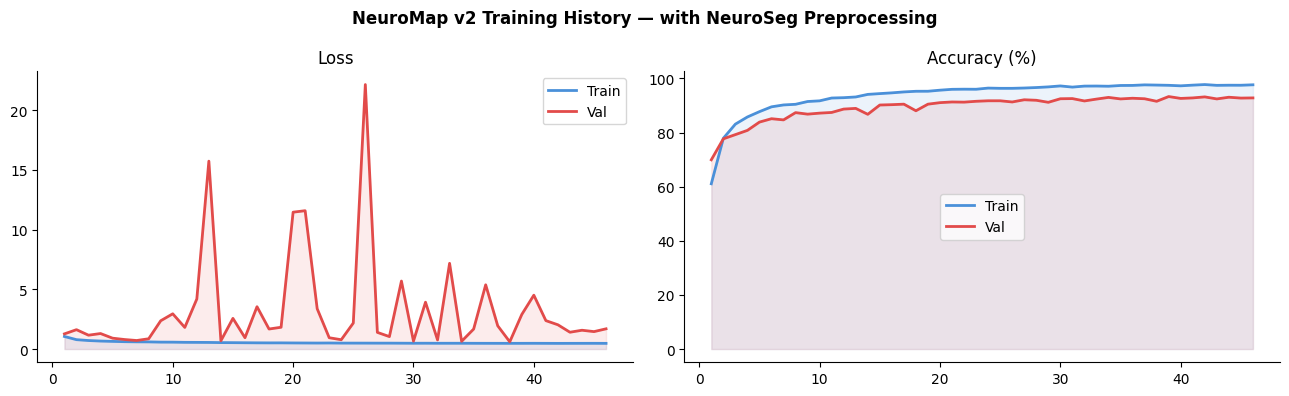

In [15]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(13,4))
fig.suptitle("NeuroMap v2 Training History — with NeuroSeg Preprocessing", fontsize=12, fontweight='bold')
ep=range(1,len(history['ta'])+1)
ax1.plot(ep,history['tl'],'#4A90D9',label='Train',lw=2); ax1.plot(ep,history['vl'],'#E24B4A',label='Val',lw=2)
ax1.fill_between(ep,history['tl'],alpha=0.1,color='#4A90D9'); ax1.fill_between(ep,history['vl'],alpha=0.1,color='#E24B4A')
ax1.set_title('Loss'); ax1.legend(); ax1.spines[['top','right']].set_visible(False)
ax2.plot(ep,[a*100 for a in history['ta']],'#4A90D9',label='Train',lw=2)
ax2.plot(ep,[a*100 for a in history['va']],'#E24B4A',label='Val',lw=2)
ax2.fill_between(ep,[a*100 for a in history['ta']],alpha=0.1,color='#4A90D9')
ax2.fill_between(ep,[a*100 for a in history['va']],alpha=0.1,color='#E24B4A')
ax2.set_title('Accuracy (%)'); ax2.legend(); ax2.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR,'training_curves.png'),dpi=150); plt.show()


## 8. Evaluation

In [16]:
ckpt=torch.load(CKPT_PATH,map_location=DEVICE)
model.load_state_dict(ckpt['model_state_dict']); model.eval()
print(f"Loaded best model  epoch={ckpt['epoch']}  val_acc={ckpt['val_acc']:.4f}")


Loaded best model  epoch=39  val_acc=0.9331


In [17]:
_,acc,fpreds,flabels=evaluate(model,test_loader,criterion,DEVICE)
print(f"Test Accuracy: {acc*100:.2f}%\n")
print(classification_report(flabels,fpreds,target_names=CLASS_NAMES,digits=4))


Test Accuracy: 93.31%

              precision    recall  f1-score   support

      glioma     0.9737    0.8325    0.8976       400
  meningioma     0.9442    0.9300    0.9370       400
     notumor     0.8879    0.9900    0.9362       400
   pituitary     0.9378    0.9800    0.9584       400

    accuracy                         0.9331      1600
   macro avg     0.9359    0.9331    0.9323      1600
weighted avg     0.9359    0.9331    0.9323      1600



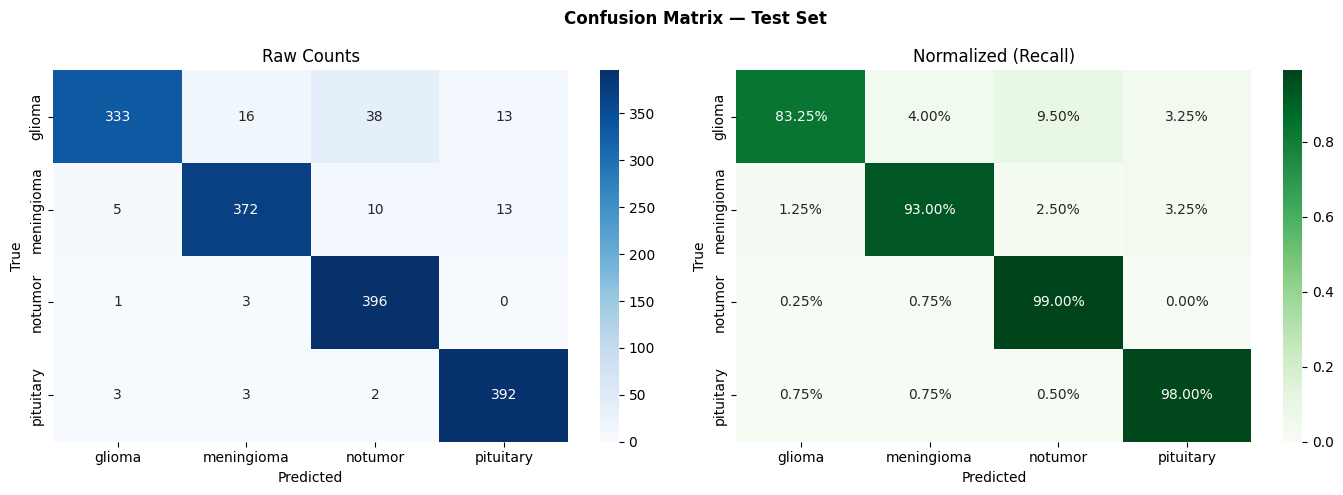

In [18]:
cm=confusion_matrix(flabels,fpreds)
fig,axes=plt.subplots(1,2,figsize=(14,5))
fig.suptitle("Confusion Matrix — Test Set",fontsize=12,fontweight='bold')
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=axes[0])
axes[0].set_ylabel('True'); axes[0].set_xlabel('Predicted'); axes[0].set_title('Raw Counts')
cm_n=cm.astype('float')/cm.sum(axis=1)[:,np.newaxis]
sns.heatmap(cm_n,annot=True,fmt='.2%',cmap='Greens',xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=axes[1])
axes[1].set_ylabel('True'); axes[1].set_xlabel('Predicted'); axes[1].set_title('Normalized (Recall)')
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR,'confusion_matrix.png'),dpi=150); plt.show()


## 9. Grad-CAM on Test Set

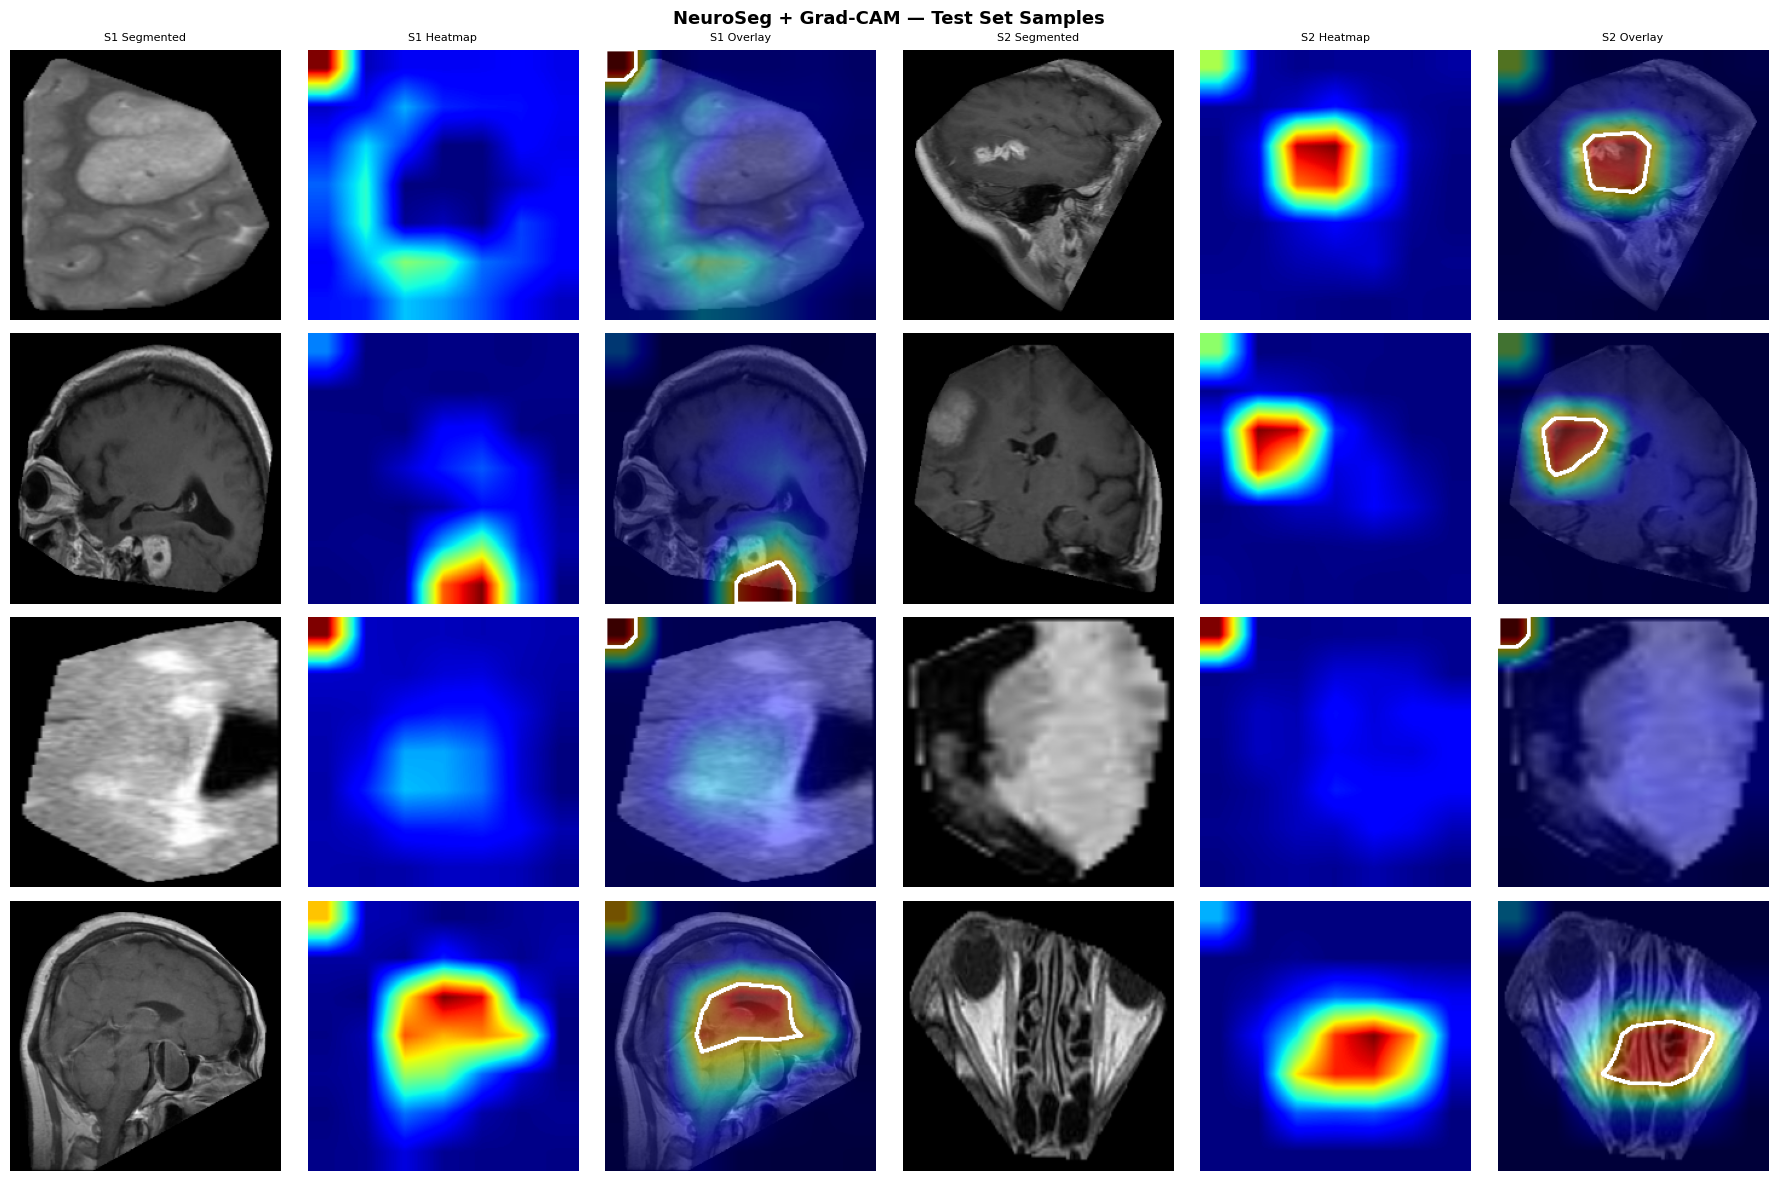

In [19]:
seg = NeuroSeg(target_size=224)
tf  = val_transforms

def get_overlay(model, img_pil, device):
    try: seg_pil,_,_ = seg.segment(img_pil)
    except: seg_pil = img_pil.resize((224,224))
    img_np = np.array(seg_pil)
    tensor = tf(seg_pil).unsqueeze(0).to(device)
    heatmap,pred_idx,probs = model.get_gradcam(tensor)
    hm = (heatmap*255).astype(np.uint8)
    hm_rgb = cv2.cvtColor(cv2.applyColorMap(hm, cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    overlay = (img_np.astype(float)*0.55 + hm_rgb.astype(float)*0.45).astype(np.uint8)
    cnts,_ = cv2.findContours((hm>int(255*0.7)).astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if cnts: cv2.drawContours(overlay,[max(cnts,key=cv2.contourArea)],-1,(255,255,255),2)
    return img_np,heatmap,overlay,pred_idx,probs

fig,axes = plt.subplots(4,6,figsize=(18,12))
fig.suptitle("NeuroSeg + Grad-CAM — Test Set Samples",fontsize=13,fontweight='bold')

for row,cls in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TEST_DIR,cls)
    files   = [f for f in os.listdir(cls_dir) if f.lower().endswith(('.jpg','.jpeg','.png'))][:2]
    for cp,fname in enumerate(files):
        img_pil = Image.open(os.path.join(cls_dir,fname)).convert('RGB')
        orig,hm,ov,pi,pr = get_overlay(model,img_pil,DEVICE)
        cb = cp*3
        axes[row][cb].imshow(orig);    axes[row][cb].axis('off')
        axes[row][cb+1].imshow(hm,cmap='jet'); axes[row][cb+1].axis('off')
        axes[row][cb+2].imshow(ov);    axes[row][cb+2].axis('off')
        c = "✓" if CLASS_NAMES[pi]==cls else "✗"
        axes[row][cb+2].set_xlabel(f"{c} {CLASS_NAMES[pi]} ({pr[pi]*100:.0f}%)",
            fontsize=8,color='green' if c=='✓' else 'red')
        if row==0:
            for j,t in enumerate(['Segmented','Heatmap','Overlay']):
                axes[row][cb+j].set_title(f"S{cp+1} {t}",fontsize=8)
    axes[row][0].set_ylabel(cls.capitalize(),fontsize=10,fontweight='bold',
                             color=CLASS_COLORS[row],rotation=90,labelpad=10)

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR,'gradcam_test_samples.png'),dpi=150); plt.show()


## 10. Single-Image Inference

In [20]:
CLASS_INFO = {
    'glioma':     {'full_name':'Glioma','severity':'High','color':'#E24B4A'},
    'meningioma': {'full_name':'Meningioma','severity':'Medium','color':'#EF9F27'},
    'pituitary':  {'full_name':'Pituitary Tumor','severity':'Medium','color':'#378ADD'},
    'notumor':    {'full_name':'No Tumor Detected','severity':'None','color':'#4CAF76'},
}

def predict(image_path, model, device):
    img_pil = Image.open(image_path).convert('RGB')
    try: seg_pil,_,_ = NeuroSeg().segment(img_pil)
    except: seg_pil = img_pil.resize((224,224))
    orig   = np.array(seg_pil)
    tensor = val_transforms(seg_pil).unsqueeze(0).to(device)
    hm,pi,pr = model.get_gradcam(tensor)
    pred = CLASS_NAMES[pi]; info = CLASS_INFO[pred]
    hm_rgb = cv2.cvtColor(cv2.applyColorMap((hm*255).astype(np.uint8),cv2.COLORMAP_JET),cv2.COLOR_BGR2RGB)
    overlay= (orig.astype(float)*0.55+hm_rgb.astype(float)*0.45).astype(np.uint8)
    return {'prediction':pred,'full_name':info['full_name'],'severity':info['severity'],
            'confidence':round(float(pr[pi])*100,2),
            'probabilities':{CLASS_NAMES[i]:round(float(pr[i])*100,2) for i in range(4)},
            'tumor_detected':pred!='notumor','original':orig,'heatmap':hm,'overlay':overlay}

print("predict() ready ✅")


predict() ready ✅


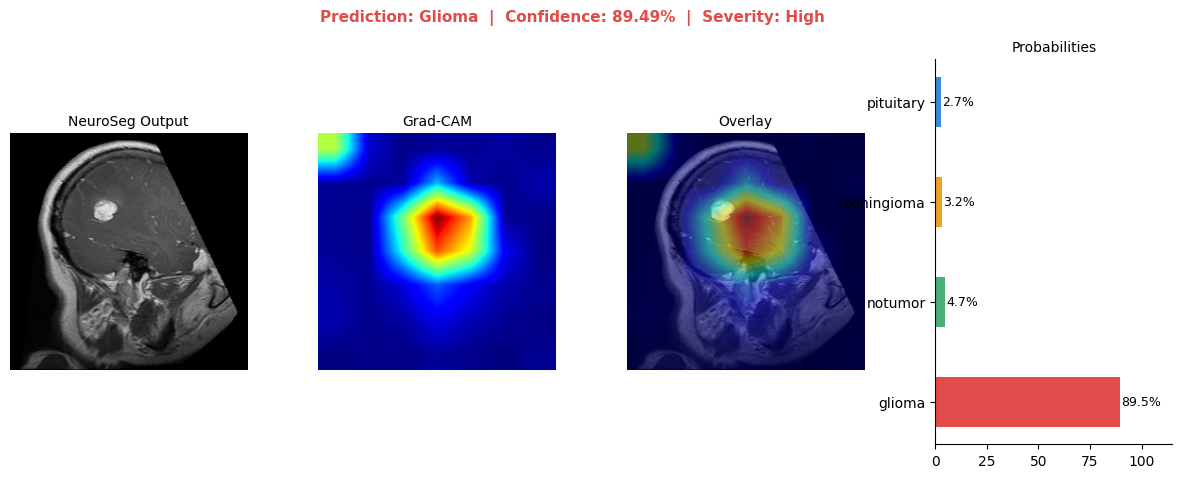

Predicted : Glioma
Confidence: 89.49%
  glioma         █████████████████░░░  89.5%
  notumor        ░░░░░░░░░░░░░░░░░░░░  4.7%
  meningioma     ░░░░░░░░░░░░░░░░░░░░  3.2%
  pituitary      ░░░░░░░░░░░░░░░░░░░░  2.7%

✅ Training complete → run app.py to start the web app


In [21]:
TEST_IMG = os.path.join(TEST_DIR, CLASS_NAMES[0],
            os.listdir(os.path.join(TEST_DIR,CLASS_NAMES[0]))[5])
result = predict(TEST_IMG, model, DEVICE)

fig = plt.figure(figsize=(15,5))
gs  = gridspec.GridSpec(1,4,figure=fig,wspace=0.3)
for i,(img,title) in enumerate([
    (result['original'],'NeuroSeg Output'),
    (result['heatmap'],'Grad-CAM'),
    (result['overlay'],'Overlay')]):
    ax=fig.add_subplot(gs[0,i]); ax.imshow(img,cmap='jet' if title=='Grad-CAM' else None)
    ax.set_title(title,fontsize=10); ax.axis('off')

ax_b=fig.add_subplot(gs[0,3])
items=sorted(result['probabilities'].items(),key=lambda x:-x[1])
colors=['#E24B4A','#EF9F27','#378ADD','#4CAF76']
CLASS_INFO_COLOR={'glioma':'#E24B4A','meningioma':'#EF9F27','pituitary':'#378ADD','notumor':'#4CAF76'}
bars=ax_b.barh([k for k,_ in items],[v for _,v in items],
               color=[CLASS_INFO_COLOR[k] for k,_ in items],height=0.5)
for b,(_,v) in zip(bars,items): ax_b.text(b.get_width()+0.5,b.get_y()+b.get_height()/2,f'{v:.1f}%',va='center',fontsize=9)
ax_b.set_xlim(0,115); ax_b.set_title('Probabilities',fontsize=10); ax_b.spines[['top','right']].set_visible(False)
fig.suptitle(f"Prediction: {result['full_name']}  |  Confidence: {result['confidence']}%  |  Severity: {result['severity']}",
             fontsize=11,fontweight='bold',color=CLASS_INFO_COLOR[result['prediction']])
plt.savefig(os.path.join(CHECKPOINT_DIR,'single_inference.png'),dpi=150,bbox_inches='tight'); plt.show()
print(f"Predicted : {result['full_name']}")
print(f"Confidence: {result['confidence']}%")
for c,p in sorted(result['probabilities'].items(),key=lambda x:-x[1]):
    print(f"  {c:<14} {'█'*int(p/5)+'░'*(20-int(p/5))}  {p:.1f}%")
print("\n✅ Training complete → run app.py to start the web app")
